<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [35]:
df=pd.read_csv('/content/drive/MyDrive/TeachingRatings.csv')
df.head()

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Question 1. Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94.

In [38]:
df[df['prof']== 'yes']
df['age'].mean()
df['age'].std()

df_unique = df.drop_duplicates(subset=['prof'])
df_unique['age'].mean()
df_unique['age'].std()

10.256513295154951

Question 2. Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations

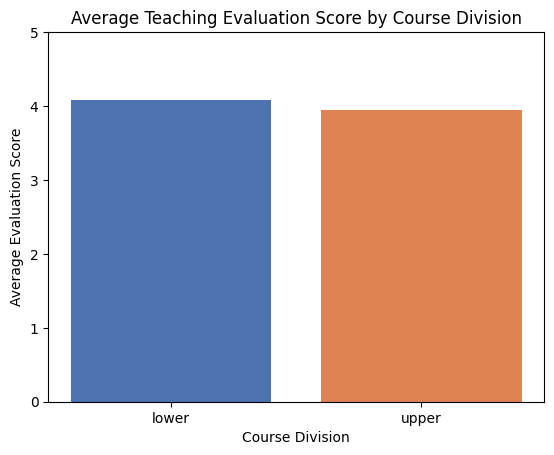

In [41]:
division_eval = df.groupby('division')['eval'].mean()

plt.bar(division_eval.index, division_eval.values, color=['#4C72B0', '#DD8452'])
plt.xlabel("Course Division")
plt.ylabel("Average Evaluation Score")
plt.title("Average Teaching Evaluation Score by Course Division")
plt.ylim(0, 5)
plt.show()

 Question 3. Plot the relationship between age and teaching evaluation scores.

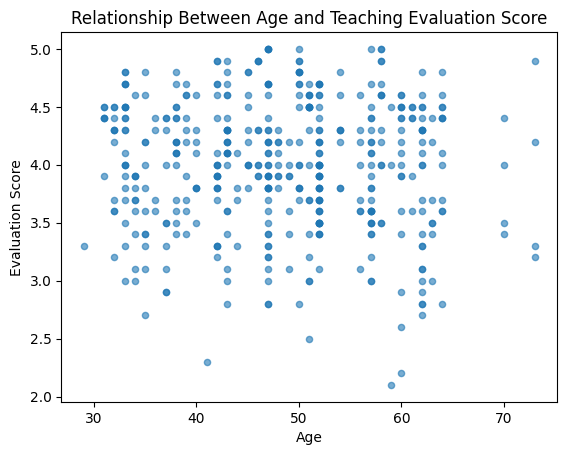

-0.051696190877182864
The scatter plot shows no clear pattern between age and evaluation score — points are scattered fairly evenly across all ages.


In [47]:
df.plot(kind='scatter', x='age', y='eval', alpha=0.6)
plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Relationship Between Age and Teaching Evaluation Score")
plt.show()
correlation = df['age'].corr(df['eval'])
print(correlation)
print("The scatter plot shows no clear pattern between age and evaluation score — points are scattered fairly evenly across all ages.")

Question 4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.

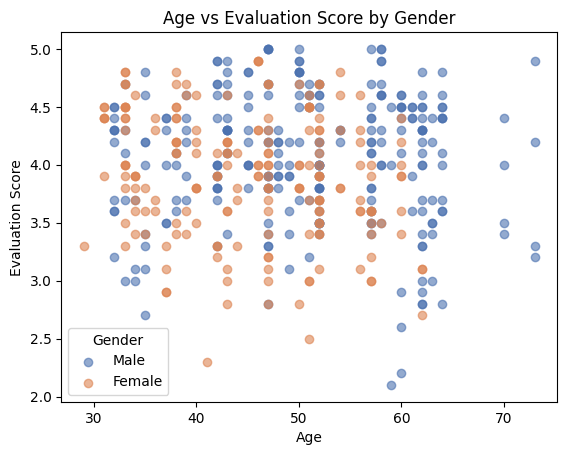

            mean       std  count
gender                           
female  3.901026  0.538803    195
male    4.069030  0.556652    268


In [46]:
males = df[df['gender'] == 'male']
females = df[df['gender'] == 'female']

plt.scatter(males['age'], males['eval'], color='#4C72B0', alpha=0.6, label='Male')
plt.scatter(females['age'], females['eval'], color='#DD8452', alpha=0.6, label='Female')

plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Age vs Evaluation Score by Gender")
plt.legend(title="Gender")
plt.show()
gender_stats = df.groupby('gender')['eval'].agg(['mean', 'std', 'count'])
print(gender_stats)

Question 5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.

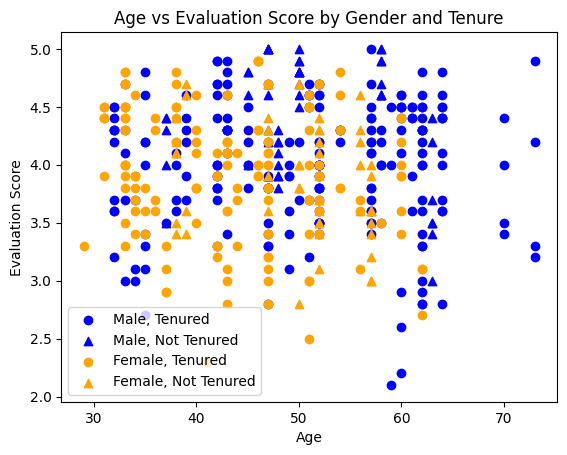

gender  tenure
female  no        3.860000
        yes       3.915172
male    no        4.396154
        yes       3.990278
Name: eval, dtype: float64
The scatterplot shows gender as the more visible pattern (male points skew slightly higher on eval,while tenure status doesn't create an obvious visual split


In [52]:
male_tenured   = df[(df['gender'] == 'male')   & (df['tenure'] == 'yes')]
male_untenured = df[(df['gender'] == 'male')   & (df['tenure'] == 'no')]
female_tenured   = df[(df['gender'] == 'female') & (df['tenure'] == 'yes')]
female_untenured = df[(df['gender'] == 'female') & (df['tenure'] == 'no')]

plt.scatter(male_tenured['age'], male_tenured['eval'], color='blue', marker='o', label='Male, Tenured')
plt.scatter(male_untenured['age'], male_untenured['eval'], color='blue', marker='^', label='Male, Not Tenured')
plt.scatter(female_tenured['age'], female_tenured['eval'], color='orange', marker='o', label='Female, Tenured')
plt.scatter(female_untenured['age'], female_untenured['eval'], color='orange', marker='^', label='Female, Not Tenured')

plt.xlabel("Age")
plt.ylabel("Evaluation Score")
plt.title("Age vs Evaluation Score by Gender and Tenure")
plt.legend()
plt.show()
tenure_gender_stats = df.groupby(['gender', 'tenure'])['eval'].mean()
print(tenure_gender_stats)
print("The scatterplot shows gender as the more visible pattern (male points skew slightly higher on eval,while tenure status doesn't create an obvious visual split")